<a href="https://colab.research.google.com/github/Fer448/curso104/blob/main/URGENCIAS_HOSPITAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Problema: Sala de Urgencias Hospitalaria
Escenario: Un hospital quiere modelar el flujo de pacientes en urgencias para optimizar recursos.

2. Código del Simulador de Colas Hospitalario

=== SIMULADOR HOSPITALARIO - TEORÍA DE COLAS ===

Generando datos hospitalarios...
Datos generados: 902 pacientes

--- ESTADÍSTICAS DESCRIPTIVAS ---
Tipos de pacientes:
tipo_paciente
1    534
2    282
3     86
Name: count, dtype: int64

Tiempo de servicio promedio: 47.96 minutos
Pacientes en horario pico: 488 (54.1%)

--- RESULTADOS DE SIMULACIÓN ---

Escenario Actual:
  Doctores: 3, Capacidad: 15
  Pacientes atendidos: 636
  Tasa de rechazo: 30.94%
  Tiempo espera promedio: 150.19 min
  Utilización: 143.04%

Más Doctores:
  Doctores: 4, Capacidad: 20
  Pacientes atendidos: 814
  Tasa de rechazo: 8.33%
  Tiempo espera promedio: 100.48 min
  Utilización: 107.28%

Menos Doctores:
  Doctores: 2, Capacidad: 10
  Pacientes atendidos: 468
  Tasa de rechazo: 47.47%
  Tiempo espera promedio: 145.17 min
  Utilización: 214.56%

Más Capacidad:
  Doctores: 3, Capacidad: 25
  Pacientes atendidos: 663
  Tasa de rechazo: 29.39%
  Tiempo espera promedio: 294.43 min
  Utilización: 143.04%

Generando vi

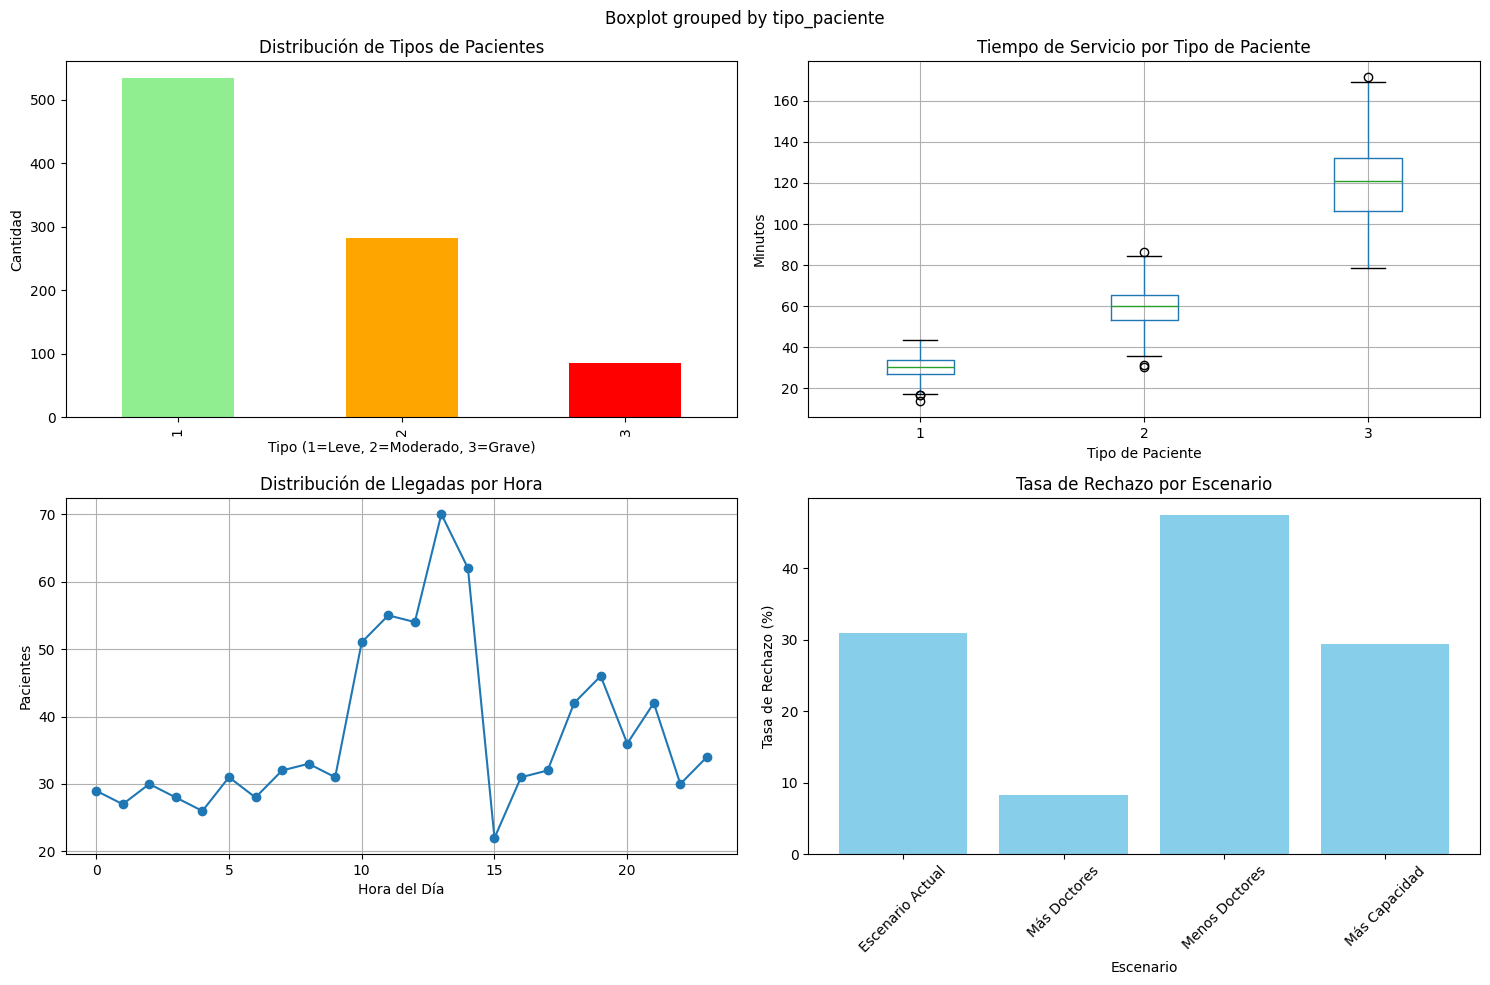


--- OPTIMIZACIÓN DE RECURSOS ---
Configuración óptima:
  Doctores: 4
  Capacidad: 14
  Costo total semanal: $21,000.00
  Pacientes rechazados: 1
  Utilización: 75.0%

=== ANÁLISIS COMPLETADO ===
Resultados guardados en:
- analisis_hospitalario.png (gráficos)
- Variables: datos, resultados, config_optima


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
import random

class SimuladorHospital:
    def __init__(self, tasa_llegada, tasa_servicio, num_servidores, capacidad_maxima=None):
        """
        Simulador del sistema de colas hospitalario

        Args:
            tasa_llegada: Pacientes por hora (lambda)
            tasa_servicio: Pacientes por hora por servidor (mu)
            num_servidores: Número de doctores/enfermeras
            capacidad_maxima: Máximo pacientes en el sistema (None = ilimitado)
        """
        self.tasa_llegada = tasa_llegada
        self.tasa_servicio = tasa_servicio
        self.num_servidores = num_servidores
        self.capacidad_maxima = capacidad_maxima

        # Estado del sistema
        self.cola = deque()
        self.servidores_ocupados = 0
        self.tiempo_actual = 0

        # Métricas
        self.pacientes_atendidos = 0
        self.pacientes_rechazados = 0
        self.tiempo_espera_total = 0
        self.tiempo_servicio_total = 0
        self.area_q = 0  # Área bajo la curva de longitud de cola
        self.area_b = 0  # Área bajo la curva de servidores ocupados

        # Eventos
        self.proximo_evento = None
        self.proxima_llegada = self.generar_llegada()
        self.proximas_salidas = [float('inf')] * num_servidores

        # Historial para análisis
        self.historial = []

    def generar_llegada(self):
        """Genera tiempo hasta la próxima llegada (distribución exponencial)"""
        return self.tiempo_actual + np.random.exponential(1/self.tasa_llegada)

    def generar_servicio(self):
        """Genera tiempo de servicio (distribución exponencial)"""
        return np.random.exponential(1/self.tasa_servicio)

    def simular(self, tiempo_simulacion):
        """Ejecuta la simulación por el tiempo especificado"""
        while self.tiempo_actual < tiempo_simulacion:
            self.registrar_estado()

            # Encuentra el próximo evento
            proxima_salida = min(self.proximas_salidas) if any(s != float('inf') for s in self.proximas_salidas) else float('inf')

            if self.proxima_llegada <= proxima_salida and self.proxima_llegada <= tiempo_simulacion:
                self.tiempo_actual = self.proxima_llegada
                self.procesar_llegada()
            elif proxima_salida <= tiempo_simulacion:
                self.tiempo_actual = proxima_salida
                self.procesar_salida()
            else:
                break

        self.calcular_metricas_finales()
        return self.obtener_metricas()

    def procesar_llegada(self):
        """Procesa la llegada de un nuevo paciente"""
        # Actualizar área bajo las curvas
        self.actualizar_areas()

        # Verificar si hay capacidad
        if self.capacidad_maxima is None or len(self.cola) + self.servidores_ocupados < self.capacidad_maxima:
            if self.servidores_ocupados < self.num_servidores:
                # Atender inmediatamente
                self.servidores_ocupados += 1
                tiempo_servicio = self.generar_servicio()
                servidor_libre = self.proximas_salidas.index(float('inf'))
                self.proximas_salidas[servidor_libre] = self.tiempo_actual + tiempo_servicio
                self.tiempo_servicio_total += tiempo_servicio
            else:
                # Ir a la cola
                self.cola.append(self.tiempo_actual)
        else:
            # Sistema lleno - paciente rechazado
            self.pacientes_rechazados += 1

        # Programar próxima llegada
        self.proxima_llegada = self.generar_llegada()

    def procesar_salida(self):
        """Procesa la salida de un paciente atendido"""
        # Actualizar área bajo las curvas
        self.actualizar_areas()

        # Encontrar servidor que termina
        servidor_idx = self.proximas_salidas.index(min(self.proximas_salidas))
        self.proximas_salidas[servidor_idx] = float('inf')
        self.servidores_ocupados -= 1
        self.pacientes_atendidos += 1

        # Atender siguiente paciente en cola
        if self.cola:
            tiempo_espera = self.tiempo_actual - self.cola.popleft()
            self.tiempo_espera_total += tiempo_espera

            self.servidores_ocupados += 1
            tiempo_servicio = self.generar_servicio()
            self.proximas_salidas[servidor_idx] = self.tiempo_actual + tiempo_servicio
            self.tiempo_servicio_total += tiempo_servicio

    def actualizar_areas(self):
        """Actualiza las áreas para calcular promedios"""
        tiempo_desde_ultimo = self.tiempo_actual - (self.historial[-1]['tiempo'] if self.historial else 0)
        self.area_q += len(self.cola) * tiempo_desde_ultimo
        self.area_b += self.servidores_ocupados * tiempo_desde_ultimo

    def registrar_estado(self):
        """Registra el estado actual del sistema"""
        self.historial.append({
            'tiempo': self.tiempo_actual,
            'longitud_cola': len(self.cola),
            'servidores_ocupados': self.servidores_ocupados,
            'pacientes_sistema': len(self.cola) + self.servidores_ocupados
        })

    def calcular_metricas_finales(self):
        """Calcula métricas finales de la simulación"""
        self.tiempo_total_simulacion = self.tiempo_actual

    def obtener_metricas(self):
        """Retorna las métricas del sistema"""
        if self.pacientes_atendidos == 0:
            return {}

        Lq = self.area_q / self.tiempo_total_simulacion  # Longitud promedio de cola
        Wq = self.tiempo_espera_total / self.pacientes_atendidos  # Tiempo promedio de espera
        ρ = self.tasa_llegada / (self.num_servidores * self.tasa_servicio)  # Utilización

        return {
            'pacientes_atendidos': self.pacientes_atendidos,
            'pacientes_rechazados': self.pacientes_rechazados,
            'tasa_rechazo': self.pacientes_rechazados / (self.pacientes_atendidos + self.pacientes_rechazados),
            'longitud_promedio_cola': Lq,
            'tiempo_espera_promedio': Wq,
            'utilizacion': ρ,
            'eficiencia': self.tiempo_servicio_total / (self.num_servidores * self.tiempo_total_simulacion)
        }

# 3. Generación de Datos Simulados
def generar_datos_hospitalarios(dias=30):
    """Genera datos simulados de un hospital"""
    np.random.seed(42)

    datos = []
    for dia in range(dias):
        # Patrón diario: más llegadas en horario pico (10am-2pm, 6pm-10pm)
        for hora in range(24):
            if 10 <= hora <= 14:  # Horario pico mañana
                tasa_llegada = np.random.poisson(8)
            elif 18 <= hora <= 22:  # Horario pico tarde
                tasa_llegada = np.random.poisson(7)
            else:  # Horario normal
                tasa_llegada = np.random.poisson(4)

            for _ in range(tasa_llegada):
                # Tipo de paciente: 1=leve, 2=moderado, 3=grave
                tipo_paciente = np.random.choice([1, 2, 3], p=[0.6, 0.3, 0.1])

                # Tiempo de servicio según gravedad (minutos)
                if tipo_paciente == 1:
                    tiempo_servicio = np.random.normal(30, 5)  # Leve: 30 min
                elif tipo_paciente == 2:
                    tiempo_servicio = np.random.normal(60, 10)  # Moderado: 1 hora
                else:
                    tiempo_servicio = np.random.normal(120, 20)  # Grave: 2 horas

                datos.append({
                    'dia': dia + 1,
                    'hora': hora,
                    'tipo_paciente': tipo_paciente,
                    'tiempo_servicio': max(10, tiempo_servicio),  # Mínimo 10 minutos
                    'horario_pico': 1 if (10 <= hora <= 14 or 18 <= hora <= 22) else 0
                })

    return pd.DataFrame(datos)

# 4. Análisis y Visualización
def analizar_sistema_hospitalario():
    """Análisis completo del sistema hospitalario"""

    # Generar datos
    print("Generando datos hospitalarios...")
    df_hospital = generar_datos_hospitalarios(7)  # 1 semana
    print(f"Datos generados: {len(df_hospital)} pacientes")

    # Estadísticas descriptivas
    print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
    print(f"Tipos de pacientes:")
    print(df_hospital['tipo_paciente'].value_counts().sort_index())
    print(f"\nTiempo de servicio promedio: {df_hospital['tiempo_servicio'].mean():.2f} minutos")
    print(f"Pacientes en horario pico: {df_hospital['horario_pico'].sum()} ({df_hospital['horario_pico'].mean()*100:.1f}%)")

    # Simulaciones para diferentes escenarios
    escenarios = [
        {"doctores": 3, "capacidad": 15, "desc": "Escenario Actual"},
        {"doctores": 4, "capacidad": 20, "desc": "Más Doctores"},
        {"doctores": 2, "capacidad": 10, "desc": "Menos Doctores"},
        {"doctores": 3, "capacidad": 25, "desc": "Más Capacidad"}
    ]

    resultados = []

    print("\n--- RESULTADOS DE SIMULACIÓN ---")
    for escenario in escenarios:
        # Tasa promedio basada en nuestros datos
        tasa_llegada_promedio = len(df_hospital) / (7 * 24)  # Pacientes por hora
        tasa_servicio_promedio = 60 / df_hospital['tiempo_servicio'].mean()  # Pacientes por hora

        simulador = SimuladorHospital(
            tasa_llegada=tasa_llegada_promedio,
            tasa_servicio=tasa_servicio_promedio,
            num_servidores=escenario["doctores"],
            capacidad_maxima=escenario["capacidad"]
        )

        metricas = simulador.simular(tiempo_simulacion=24 * 7)  # Simular 1 semana

        resultado = {
            'escenario': escenario["desc"],
            'doctores': escenario["doctores"],
            'capacidad': escenario["capacidad"],
            **metricas
        }
        resultados.append(resultado)

        print(f"\n{escenario['desc']}:")
        print(f"  Doctores: {escenario['doctores']}, Capacidad: {escenario['capacidad']}")
        print(f"  Pacientes atendidos: {metricas.get('pacientes_atendidos', 0)}")
        print(f"  Tasa de rechazo: {metricas.get('tasa_rechazo', 0)*100:.2f}%")
        print(f"  Tiempo espera promedio: {metricas.get('tiempo_espera_promedio', 0)*60:.2f} min")
        print(f"  Utilización: {metricas.get('utilizacion', 0)*100:.2f}%")

    # Visualizaciones
    print("\nGenerando visualizaciones...")
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Distribución de tipos de pacientes
    df_hospital['tipo_paciente'].value_counts().sort_index().plot(
        kind='bar', ax=ax1, color=['lightgreen', 'orange', 'red']
    )
    ax1.set_title('Distribución de Tipos de Pacientes')
    ax1.set_xlabel('Tipo (1=Leve, 2=Moderado, 3=Grave)')
    ax1.set_ylabel('Cantidad')

    # 2. Tiempos de servicio por tipo
    df_hospital.boxplot(column='tiempo_servicio', by='tipo_paciente', ax=ax2)
    ax2.set_title('Tiempo de Servicio por Tipo de Paciente')
    ax2.set_xlabel('Tipo de Paciente')
    ax2.set_ylabel('Minutos')

    # 3. Distribución horaria
    df_hospital['hora'].value_counts().sort_index().plot(ax=ax3, kind='line', marker='o')
    ax3.set_title('Distribución de Llegadas por Hora')
    ax3.set_xlabel('Hora del Día')
    ax3.set_ylabel('Pacientes')
    ax3.grid(True)

    # 4. Comparación de escenarios
    df_resultados = pd.DataFrame(resultados)
    x_pos = range(len(df_resultados))
    ax4.bar(x_pos, df_resultados['tasa_rechazo']*100, color='skyblue')
    ax4.set_title('Tasa de Rechazo por Escenario')
    ax4.set_xlabel('Escenario')
    ax4.set_ylabel('Tasa de Rechazo (%)')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(df_resultados['escenario'], rotation=45)

    plt.tight_layout()
    plt.savefig('analisis_hospitalario.png', dpi=300, bbox_inches='tight')
    plt.show()

    return df_hospital, pd.DataFrame(resultados)

# 5. Función de Optimización
def optimizar_recursos():
    """Encuentra la configuración óptima de recursos"""
    print("\n--- OPTIMIZACIÓN DE RECURSOS ---")

    # Parámetros basados en datos reales
    costo_doctor = 5000  # $ por semana
    costo_rechazo = 1000  # $ costo oportunidad por paciente rechazado
    tasa_llegada = 6  # pacientes/hora
    tasa_servicio = 2  # pacientes/hora por doctor

    mejor_config = None
    mejor_costo = float('inf')

    for doctores in range(2, 8):
        for capacidad in range(doctores + 5, doctores + 15, 5):
            simulador = SimuladorHospital(
                tasa_llegada=tasa_llegada,
                tasa_servicio=tasa_servicio,
                num_servidores=doctores,
                capacidad_maxima=capacidad
            )

            metricas = simulador.simular(24 * 7)  # 1 semana

            if metricas:
                costo_total = (doctores * costo_doctor +
                             metricas['pacientes_rechazados'] * costo_rechazo)

                if costo_total < mejor_costo:
                    mejor_costo = costo_total
                    mejor_config = {
                        'doctores': doctores,
                        'capacidad': capacidad,
                        'costo_total': costo_total,
                        'pacientes_rechazados': metricas['pacientes_rechazados'],
                        'utilizacion': metricas['utilizacion']
                    }

    print(f"Configuración óptima:")
    print(f"  Doctores: {mejor_config['doctores']}")
    print(f"  Capacidad: {mejor_config['capacidad']}")
    print(f"  Costo total semanal: ${mejor_config['costo_total']:,.2f}")
    print(f"  Pacientes rechazados: {mejor_config['pacientes_rechazados']}")
    print(f"  Utilización: {mejor_config['utilizacion']*100:.1f}%")

    return mejor_config

# 6. Ejecución completa
if __name__ == "__main__":
    print("=== SIMULADOR HOSPITALARIO - TEORÍA DE COLAS ===\n")

    # Análisis completo
    datos, resultados = analizar_sistema_hospitalario()

    # Optimización
    config_optima = optimizar_recursos()

    print("\n=== ANÁLISIS COMPLETADO ===")
    print("Resultados guardados en:")
    print("- analisis_hospitalario.png (gráficos)")
    print("- Variables: datos, resultados, config_optima")

7. Análisis de Resultados Adicional



In [2]:
# Análisis avanzado de sensibilidad
def analisis_sensibilidad():
    """Analiza sensibilidad a cambios en parámetros"""
    parametros_base = {
        'tasa_llegada': 6,
        'tasa_servicio': 2,
        'doctores': 3,
        'capacidad': 15
    }

    variaciones = []

    # Variar tasa de llegada
    for factor in [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]:
        tasa = parametros_base['tasa_llegada'] * factor

        simulador = SimuladorHospital(
            tasa_llegada=tasa,
            tasa_servicio=parametros_base['tasa_servicio'],
            num_servidores=parametros_base['doctores'],
            capacidad_maxima=parametros_base['capacidad']
        )

        metricas = simulador.simular(24 * 7)

        if metricas:
            variaciones.append({
                'parametro': 'tasa_llegada',
                'factor': factor,
                'valor': tasa,
                'tasa_rechazo': metricas['tasa_rechazo'],
                'tiempo_espera': metricas['tiempo_espera_promedio'],
                'utilizacion': metricas['utilizacion']
            })

    df_sensibilidad = pd.DataFrame(variaciones)

    # Graficar sensibilidad
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    df_sensibilidad.plot(x='factor', y='tasa_rechazo', ax=axes[0], marker='o')
    axes[0].set_title('Sensibilidad: Tasa de Rechazo vs Factor de Carga')
    axes[0].set_xlabel('Factor de Carga')
    axes[0].set_ylabel('Tasa de Rechazo')
    axes[0].grid(True)

    df_sensibilidad.plot(x='factor', y='tiempo_espera', ax=axes[1], marker='o', color='red')
    axes[1].set_title('Sensibilidad: Tiempo de Espera vs Factor de Carga')
    axes[1].set_xlabel('Factor de Carga')
    axes[1].set_ylabel('Tiempo de Espera (horas)')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    return df_sensibilidad

# Ejecutar análisis de sensibilidad
# df_sens = analisis_sensibilidad()

Características principales del simulador:
Modelado realista: Patrones horarios, tipos de pacientes, tiempos de servicio variables

Métricas clave: Tiempos de espera, tasas de rechazo, utilización, longitud de cola

Análisis comparativo: Diferentes escenarios de recursos

Optimización: Encuentra configuración óptima considerando costos

Visualización: Gráficos informativos para toma de decisiones

Este sistema permite al hospital entender su operación actual y evaluar diferentes estrategias de mejora antes de implementarlas en la realidad.